<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-02, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [ ]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [ ]:
# Load data Train.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'
url

df = pd.read_csv(
    url,
    usecols=range(20),
    nrows=1_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


In [ ]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184


In [ ]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
995,995,train_995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,996,train_996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,997,train_997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,998,train_998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496
999,999,train_999,0,10.5495,2.3825,8.0625,5.4776,9.2568,13.7043,8.1997,28.6449,32.1460,5.7252,-10.5380,16.8766,11.9905,-25.7403,13.1973,5.7198,2.8214


In [ ]:
# Shape of the dataframe
df.shape

(1000, 20)

In [ ]:
# Size of the dataframe
df.size

20000

### Summary Meta-Data

In [ ]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   ID_code     1000 non-null   object 
 2   target      1000 non-null   int64  
 3   var_0       1000 non-null   float64
 4   var_1       1000 non-null   float64
 5   var_2       1000 non-null   float64
 6   var_3       1000 non-null   float64
 7   var_4       1000 non-null   float64
 8   var_5       1000 non-null   float64
 9   var_6       1000 non-null   float64
 10  var_7       1000 non-null   float64
 11  var_8       1000 non-null   float64
 12  var_9       1000 non-null   float64
 13  var_10      1000 non-null   float64
 14  var_11      1000 non-null   float64
 15  var_12      1000 non-null   float64
 16  var_13      1000 non-null   float64
 17  var_14      1000 non-null   float64
 18  var_15      1000 non-null   float64
 19  var_16      1000 non-null   

### Summary Statistics

In [ ]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.097000,10.647679,-1.648351,10.614775,5.403146,7.594834,14.016787,8.452692,15.401296,16.980541,4.309364,-4.277935,14.884472,11.447819,-7.126485,9.040722,6.002673,12.228451
std,288.819436,0.296106,3.046156,4.133810,2.548399,0.852977,1.239705,0.193809,4.511940,7.927170,8.176076,2.856678,6.049009,4.423330,0.549439,8.493894,5.845390,0.757023,7.561044
min,0.000000,0.000000,2.825300,-13.202600,4.027300,2.897800,4.469300,13.553700,-3.681900,-7.903300,-4.086700,-3.420500,-23.001300,2.535400,10.118600,-27.533500,-6.409200,4.074600,-9.602000
25%,249.750000,0.000000,8.418225,-4.858000,8.619500,4.787975,6.632325,13.882175,5.154925,9.544700,11.173075,2.199350,-8.666150,11.585500,11.031225,-13.518725,5.429900,5.412125,6.542725
50%,499.500000,0.000000,10.460250,-1.760000,10.560900,5.412450,7.648150,14.020850,8.449650,15.089200,17.064400,4.242050,-4.546300,14.536600,11.444350,-6.848250,9.515450,6.034850,12.285650
75%,749.250000,0.000000,12.656275,1.394700,12.455325,5.987425,8.641275,14.154650,11.983350,21.644800,23.001475,6.270100,-0.250150,18.375850,11.902675,-1.114775,12.996675,6.513875,17.510250
max,999.000000,1.000000,19.122300,8.416000,18.108400,7.875500,10.598200,14.501000,19.183400,35.052600,49.044300,12.285300,11.465400,26.928200,12.762200,14.544700,25.969800,7.846700,33.624800


### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

### Target Value Counts

Binary numerical classification and no nulls.

In [ ]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
0,903
1,97


### Normalize The Data

In [ ]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
0,0.903
1,0.097


### Nulls
No imputation because no nulls.

In [ ]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


Column Data Types

In [ ]:
# Display data types
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


In [ ]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,1000
ID_code,1000
var_13,1000
var_14,999
var_6,998
var_8,998
var_7,998
var_10,997
var_16,997
var_9,996


## Data Cleaning


### Backup #1

In [ ]:
# Make backup
df_bak = df.copy()

In [ ]:
# Restore from backup
df = df_bak.copy()

### Keep Only the Target and Features

In [ ]:
# Select the target and features
df = df[['target'] + [f'var_{i}' for i in range(17)]]
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,0,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,0,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,0,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


### Backup #2

In [ ]:
# Make 2nd backup
df_bak_2 = df.copy()

In [ ]:
# Restore from 2nd backup
df = df_bak_2.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

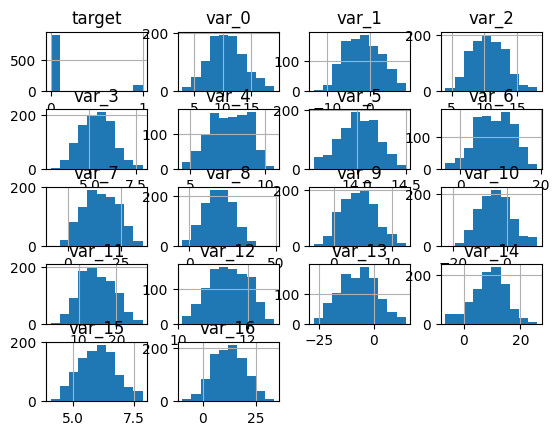

In [ ]:
# Display a histogram
df.hist() ;

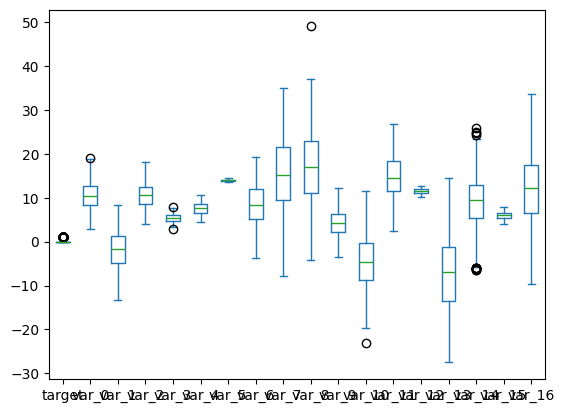

In [ ]:
# Display a box and whisker plot
df.plot(kind='box') ;

### Correlation: Independence of Features

In [ ]:
# Calculate a correlation matrix
iso_features = df[['target'] + [f'var_{i}' for i in range(17)]]

corr_mat = iso_features.corr()

corr_mat

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
target,1.000000,-0.017817,0.101429,0.025716,-0.011348,-0.005215,-0.088978,-0.034422,0.028374,-0.030690,0.059438,0.024611,-0.088169,-0.034156,0.032045,-0.033832,0.009989,0.086618
var_0,-0.017817,1.000000,0.016709,0.033530,-0.041718,-0.029472,0.031765,-0.031768,0.053884,-0.001246,-0.041087,0.012658,0.040331,-0.016348,0.001870,-0.045511,-0.030945,0.000387
var_1,0.101429,0.016709,1.000000,0.054599,0.004523,-0.060222,0.029673,-0.009913,-0.013886,0.012571,0.019991,-0.015433,0.036771,-0.006590,0.050830,-0.054055,-0.002712,0.056096
var_2,0.025716,0.033530,0.054599,1.000000,-0.015892,0.007115,0.018316,-0.028780,-0.016959,-0.028103,0.031280,0.010854,0.011465,0.000913,-0.013533,0.012850,-0.059216,0.029235
var_3,-0.011348,-0.041718,0.004523,-0.015892,1.000000,-0.013690,0.005885,-0.001661,-0.018431,0.019194,0.033903,-0.025975,-0.021268,-0.029692,0.022048,-0.026840,-0.017160,-0.028598
var_4,-0.005215,-0.029472,-0.060222,0.007115,-0.013690,1.000000,-0.054929,0.018787,-0.048617,-0.025843,-0.002610,-0.009370,-0.015352,-0.040256,-0.023076,-0.011870,0.019113,-0.051219
var_5,-0.088978,0.031765,0.029673,0.018316,0.005885,-0.054929,1.000000,-0.003199,0.009396,0.009989,0.002301,-0.027920,0.003701,-0.023235,0.034798,0.013219,-0.037258,0.020763
var_6,-0.034422,-0.031768,-0.009913,-0.028780,-0.001661,0.018787,-0.003199,1.000000,-0.014602,-0.000257,0.005024,0.013592,-0.058749,-0.053371,-0.022342,-0.008460,0.001974,-0.002136
var_7,0.028374,0.053884,-0.013886,-0.016959,-0.018431,-0.048617,0.009396,-0.014602,1.000000,-0.067479,0.019505,0.025885,0.031629,-0.004120,0.009993,0.014491,0.011159,0.015657
var_8,-0.030690,-0.001246,0.012571,-0.028103,0.019194,-0.025843,0.009989,-0.000257,-0.067479,1.000000,0.016724,0.005545,-0.013643,-0.013057,0.060894,0.043611,-0.047564,-0.016875


Text(0.5, 23.52222222222222, 'Features')

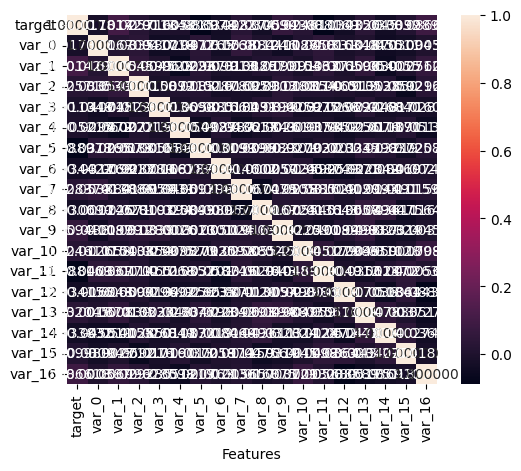

In [ ]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [ ]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [ ]:
# Split data frame into target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [ ]:
# Verify the target
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [ ]:
# Verify the features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16
0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,-5.1488,16.8911,11.1920,-5.2387,11.6418,5.1736,22.4321
1,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,-11.7684,19.3710,11.3702,-11.1147,1.2444,6.6885,7.9344
2,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,-7.9940,19.0422,11.0449,-13.5174,4.1006,6.4059,9.8565
3,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,0.8135,6.1796,10.6093,-3.8294,8.0485,5.2091,23.6143
4,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,3.1736,19.3239,12.4057,-5.5963,6.9087,5.7555,1.6184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,10.5429,-3.1313,10.3739,4.3798,9.0138,14.2108,5.6618,7.6517,19.3311,6.2302,-12.5961,21.2310,10.9861,-23.1897,1.5943,5.1007,-2.5036
996,12.9541,-3.5607,9.7151,5.3609,5.4369,13.7852,10.7173,21.3798,21.1709,9.5601,-10.3499,19.2482,11.7017,-13.8955,9.6203,5.2604,11.5526
997,4.2341,-8.5367,12.5934,5.4229,7.1058,14.4427,2.3831,17.1287,13.0236,7.6927,-9.0699,15.5518,11.9697,-13.3420,11.4566,5.5599,0.7550
998,18.5600,2.3607,9.7861,7.4188,6.3675,14.3499,13.4479,24.5266,18.8782,3.8359,-13.2004,15.8111,10.7356,-12.2080,13.5891,6.1986,10.8496


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [ ]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [ ]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [ ]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(750, 17)
<class 'pandas.core.frame.DataFrame'>
(250, 17)
<class 'pandas.core.frame.DataFrame'>
(750,)
<class 'pandas.core.series.Series'>
(250,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [ ]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [ ]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0, 1000,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0, 1000,   

#### Calculate and report the accuracy.

In [ ]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

90.0

#### Present a confusion matrix and heatmap

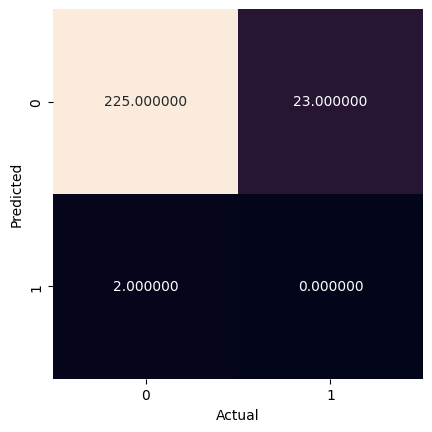

In [ ]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95       227
           1       0.00      0.00      0.00        23

    accuracy                           0.90       250
   macro avg       0.45      0.50      0.47       250
weighted avg       0.82      0.90      0.86       250



## Data Visualization/Communication of Results


### Data Visualization

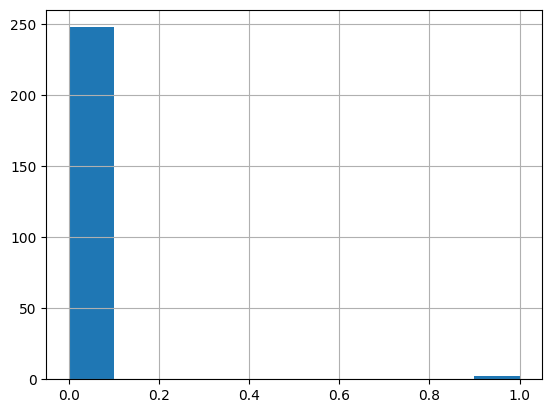

In [ ]:
# Display a histogram of the results
pd.Series(pred_results).hist() ;

## Conclusion

### Communication of Results

- var_0 thru var_16 gave us 90% accuracy
- Bad at predicting no-transactions
- Excellent at predicting a successful transaction

### Future work


- For Pass-03, use all columns and rows
- Balance the dataset (way more unsuccessful transactions vs. successful transactions)